# Feature engineering and feature selection for meta-labeling — STRATEGY_432_BTC on ETHUSDT volume bars

**Question.** The dataset carries a large feature set (240 registry columns plus 12 strategy features). For the meta-label of the existing
QuantForge workflow, which features or feature groups carry out-of-sample information, which are redundant or uninformative, and does any
justified smaller set beat the full eligible set under one fixed classifier and one evaluation protocol?

**Setup reused from the existing workflow** (`research/cross-validation/threshold_picking.ipynb`, same dataset route):

* primary model `quant_forge.strategies.Strategies.STRATEGY_432_BTC` (Donchian breakout continuation, long-only), `fee_bps=5`, library defaults;
* meta-label `y = 1[trade_return > 0]`: the trade's **net** return (simulator costs included) is positive — AFML §3.6 meta-labeling with the barriers equal to the strategy's real exit;
* chronological 70 / 30 split into *development* and *final test*, development events purged if their `[decision_time, exit_time]` reaches the test period;
* `quant_forge.validation.PurgedKFold` (5 folds, `pct_embargo = 0.02`, never shuffled) for every cross-validation.

**Not in scope** (by request): thresholds, bet sizing, PnL or any economic optimisation. All scores are classification scores of the probability
`P(y = 1)`: log loss (primary, a proper scoring rule, the score AFML Snippet 8.3 uses for MDA), Brier score and ROC-AUC.

### What comes from the attached source and what is my choice

| Element | Source: López de Prado, *Advances in Financial Machine Learning* (AFML) | My experimental choice |
|---|---|---|
| Meta-label | §3.6: secondary model learns whether to act on the primary's signal; `bin = 1` iff the side-adjusted return is positive | target and strategy taken unchanged from the existing workflow |
| Stationarity | ch. 5: non-stationary levels need differentiation; fractional differentiation (FFD, Snippet 5.3) with the minimum `d` that passes ADF (Snippet 5.4) keeps memory | raw price levels are dropped; one FFD feature of log price is added; `d` is chosen inside each training partition; currency-denominated levels are replaced by their scale-free counterparts |
| Sample weights | ch. 4: weight by uniqueness when labels overlap; `max_samples = avgU` | trades here never overlap (checked below), so average uniqueness is 1 and no weighting is applied |
| Classifier | ch. 6 (Snippet 6.2, §6.4): RF with `criterion='entropy'`, `class_weight='balanced_subsample'`, early stopping via `min_weight_fraction_leaf`; bagging preferred to boosting | 300 trees, `min_weight_fraction_leaf=0.05`, `max_features='sqrt'`, fixed a priori, no tuning |
| Cross-validation | ch. 7: purged K-fold with embargo | QuantForge's `PurgedKFold`, preprocessing and selection fitted on training rows only, nested selection |
| MDI | §8.3.1: in-sample, tree-only, `max_features=1` to avoid masking, zero importances → NaN | 1000-tree forest |
| MDA | §8.3.2: OOS permutation importance under purged CV, log loss; substitution effects can make correlated features look irrelevant | 5 permutations per fold; raw increase in log loss reported (the book divides by the permuted score; ranking is the same) |
| SFI | §8.4.1: one feature at a time, OOS, no substitution effects but loses joint effects | — |
| Orthogonal features | §8.4.2: standardise, PCA, keep 95 % of variance; weighted Kendall's τ between importance and PCA rank as evidence against overfitting (Snippet 8.6) | label-permutation null for τ |
| Synthetic noise features | §8.6 tests the methods with known noise features | **placebo** features (circularly shifted real features) inside every importance run, as the null for "important" |
| Correlated features / joint effects | the book names substitution effects and PCA as a partial fix | **clustered MDA** (permute a correlation cluster jointly) and **family MDA** (permute a registry family jointly); a cluster-representative set. (Clustered importance appears in later work by the same author, not in this book.) |
| Compared feature sets | — | full eligible set vs. four alternatives fixed before any result: incumbent list, cluster representatives, clustered-MDA selection, PCA 95 % |

## 0. Configuration

Everything that could be tuned is fixed here, before any result. No result is hard-coded in the notebook.

In [1]:
# ---- configuration -----------------------------------------------------------------------------
DATASET_NAME = "6a915d3a25d574ce"      # folder under data/crypto_dataset_pipeline/data/datasets (same route as threshold_picking.ipynb)
DATASET_FILE = "volume.parquet"
REGISTRY_FILE = "volume_registry.json"
FEE_BPS = 5                            # existing workflow
TEST_SIZE = 0.30                       # existing workflow: chronological 70 / 30, never shuffled

N_SPLITS = 5                           # outer PurgedKFold on development events
PCT_EMBARGO = 0.02                     # embargo = floor(n * 0.02) observations (existing workflow)
INNER_SPLITS = 4                       # inner PurgedKFold used by the supervised selection, inside each outer training partition

MIN_COVERAGE = 0.70                    # a column must be non-null on >= 70 % of the TRAINING rows to be used in that fit
CLUSTER_MAX_DIST = 0.30                # average-linkage clusters on 1 - |Spearman rho|: members correlate ~|rho| >= 0.7 on average
PCA_VAR = 0.95                         # AFML Snippet 8.5 default
FFD_THRESH = 1e-4                      # weight cut-off of the fixed-width FFD window (AFML Snippet 5.3 uses 1e-5 by default, 1e-2 on daily data)
FFD_D_GRID = [round(0.1 * i, 1) for i in range(11)]
FFD_BLOCK_GAP_DAYS = 30                # training rows separated by a larger gap form separate blocks for the ADF test

N_PLACEBO = 10                         # placebo features per importance run
N_PERM = 5                             # permutations per fold for MDA (descriptive section)
N_PERM_INNER = 3                       # permutations per inner fold for the nested supervised selection
N_TAU_NULL = 20                        # label permutations for the weighted Kendall tau null
SEEDS = [42, 43, 44]                   # classifier / permutation seeds for the nested comparison
SEED = SEEDS[0]
N_BOOT = 2000                          # monthly-block bootstrap resamples for confidence intervals
N_JOBS = -1

In [2]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import weightedtau
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller

try:                                   # normal case: `pip install -e .` was run
    import quant_forge
except ModuleNotFoundError:            # fallback: the repository checkout this notebook lives in
    _root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "quant_forge" / "__init__.py").exists())
    sys.path.insert(0, str(_root))
import quant_forge.strategies as qs
from quant_forge.validation import PurgedKFold

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
T0 = time.time()
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.0.2


## 1. Data, primary strategy, meta-label and chronological split

The strategy is run on the full bar frame (as in the existing workflow). Every dataset column that is a registry feature is requested as a
`context_column`, i.e. copied **from the signal bar**; `close` is requested only to build price-normalised features and is never a model input.

In [3]:
def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATA_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets" / DATASET_NAME
bars = pd.read_parquet(DATA_DIR / DATASET_FILE)
registry = pd.DataFrame(json.loads((DATA_DIR / REGISTRY_FILE).read_text())).set_index("name")
manifest = json.loads((DATA_DIR / "manifest.json").read_text())

df = bars.set_index(pd.to_datetime(bars["bar_end_us"], unit="us", utc=True)).sort_index().rename_axis("datetime")
n_dup = int(df.index.duplicated().sum())
df = df[~df.index.duplicated(keep="first")]          # same rule as the existing workflow

REG_COLS = [c for c in registry.index if c in df.columns]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                  # pandas fragmentation warnings from adding ~240 context columns
    result = qs.run_strategy(df, qs.Strategies.STRATEGY_432_BTC, fee_bps=FEE_BPS, context_columns=REG_COLS + ["close"])
trades = result.closed_trades_frame().sort_values("decision_time").reset_index(drop=True).copy()
STRATEGY_FEATURES = list(result.feature_columns)

inst = manifest["instrument"]
print(f"dataset   : {DATA_DIR.relative_to(ROOT)}  ({inst['symbol']} {inst['market_type']}, "
      f"{manifest['series']['volume']['identity']['bar_type']} bars of {manifest['series']['volume']['identity']['threshold']} {inst['base']})")
print(f"bars      : {len(df):,} ({df.index.min()} .. {df.index.max()}); {n_dup} duplicated bar_end timestamps dropped")
print(f"timing    : decision_time_us - bar_end_us = {(df['decision_time_us'] - df['bar_end_us']).abs().max()} us "
      f"(manifest decision_latency {manifest['config']['timing']['decision_latency']}, strictness '{manifest['strictness']}')")
print(f"trades    : {len(trades)} closed; sides {trades['side'].value_counts().to_dict()}; profitable share {trades['trade_return'].gt(0).mean():.3f}")
print(f"features  : {len(STRATEGY_FEATURES)} strategy features + {len(REG_COLS)} registry columns requested as context")

dataset   : data/crypto_dataset_pipeline/data/datasets/6a915d3a25d574ce  (ETHUSDT spot, volume bars of 4.9E+3 ETH)
bars      : 182,698 (2021-09-01 00:05:04.669000+00:00 .. 2026-08-31 23:14:01.553750+00:00); 5 duplicated bar_end timestamps dropped
timing    : decision_time_us - bar_end_us = 0 us (manifest decision_latency 0ms, strictness 'strict')
trades    : 1091 closed; sides {1: 1091}; profitable share 0.481
features  : 12 strategy features + 240 registry columns requested as context


In [4]:
# chronological split exactly as in the existing workflow -- never shuffled
dev_all, test_events = train_test_split(trades, test_size=TEST_SIZE, shuffle=False)
test_start = test_events["decision_time"].iloc[0]
dev = dev_all.loc[dev_all["exit_time"] < test_start].copy()          # purge development events whose label reaches the test period
test_events = test_events.copy()
assert dev["decision_time"].max() < test_start and (dev["exit_time"] < test_start).all()

for frame in (dev, test_events):
    frame.index = pd.DatetimeIndex(frame["decision_time"], name="event_start")
y_dev = dev["trade_return"].gt(0).astype("int8")
y_test = test_events["trade_return"].gt(0).astype("int8")
t1_dev = pd.Series(pd.DatetimeIndex(dev["exit_time"]), index=dev.index, name="event_end")   # PurgedKFold input

# AFML ch. 4: overlapping labels would call for uniqueness weights. Check concurrency of the label intervals.
s_ns, e_ns = pd.DatetimeIndex(trades["decision_time"]).asi8, pd.DatetimeIndex(trades["exit_time"]).asi8
n_overlap = int((s_ns[1:] <= np.maximum.accumulate(e_ns)[:-1]).sum())
print(f"label intervals that overlap an earlier one: {n_overlap}  -> average uniqueness = "
      f"{'1 (no sample weights needed)' if n_overlap == 0 else 'below 1: weights would be needed'}")
pd.DataFrame({
    "events": [len(dev_all), len(dev), len(test_events)],
    "first decision": [dev_all.decision_time.min(), dev.decision_time.min(), test_events.decision_time.min()],
    "last decision": [dev_all.decision_time.max(), dev.decision_time.max(), test_events.decision_time.max()],
    "profitable share": [dev_all.trade_return.gt(0).mean(), y_dev.mean(), y_test.mean()],
}, index=["development (before purge)", "development (eligible)", "final test"]).round(4)

label intervals that overlap an earlier one: 0  -> average uniqueness = 1 (no sample weights needed)


,events,first decision,last decision,profitable share
development (before purge),763,2021-09-01 05:52:16.156000+00:00,2025-02-17 08:50:09.791283+00:00,0.4784
development (eligible),763,2021-09-01 05:52:16.156000+00:00,2025-02-17 08:50:09.791283+00:00,0.4784
final test,328,2025-02-17 14:10:21.275987+00:00,2026-08-30 16:12:40.771783+00:00,0.4878


## 2. Feature inventory and eligibility at prediction time

**Prediction time** is the signal bar's decision time (`max(bar_end, bar_available, decision_time)`; latency is 0 in this build, so it is the bar close).
The entry fills at the next bar's first trade at or after that time. Every candidate feature must be known at that time:

* **Strategy outputs** (`result.post_decision_columns`: entry/exit prices and times, returns, labels, PnL, holding time…) are outcomes or execution information and are
  never candidates; the library separates them from `result.model_input_columns` (asserted below).
* **Registry columns** are built by the dataset pipeline in strict point-in-time mode (`strict_eligible` is true for every column; each column's
  `availability` rule is listed below, e.g. *bar close*, *day end + finalization delay*, *first verifiable availability*). They are copied from the signal bar.
* Bar identity, timestamps, trade ids and OHLC/volume are not features (OHLC are price levels; `volume` is constant by construction of volume bars).

On top of point-in-time availability, three a-priori rules (no data inspection) remove columns, following AFML ch. 5 on stationarity:

1. **Raw price levels** (Donchian bounds, trend EMA, ATR in USDT) are non-stationary; their scale-free versions (`atr_rel`, `ema_distance`, `long_breakout_atr`, DI/ADX) stay.
2. **Currency-denominated levels** that scale with the price (USDT notional flows, the USDT spread, ETF USD levels) are dropped where a scale-free counterpart exists
   (ETH-volume flows and imbalance ratios, `quote_spread_bps`, ETF z-scores).
3. **Kyle's λ** (USDT per ETH) is replaced by an engineered price-normalised version `1e4 · λ / close` (relative impact per ETH, bps). *My choice.*
4. **Staleness columns of dead feeds** (*my choice, added after a first run*): `fear_greed_value_age_s` / `_economic_age_d` are non-null although the
   Fear & Greed value is null on ~99 % of bars; they then count the days since the last verifiable publication (rising to ~800 days), i.e. they are a
   calendar clock. In a first execution they clustered with the price-level proxies. The rule is label-free: drop an age column whose base value has
   < 70 % coverage on development-period bars.

Columns whose registry status is `unavailable_from_current_source` contain no data in this build and are excluded. Columns that are sparse **on the
events** are not removed here: the coverage filter (`>= 70 %` non-null) is part of the preprocessing and is fitted on each training partition.

In [5]:
PRICE_LEVEL = ["dc_high", "dc_low", "ema_trend", "atr_value"]
SHORT_SIDE = ["short_breakout_atr"]                      # long-only run (asserted below)
CURRENCY_SCALED = ["aggr_buy_notional", "aggr_sell_notional", "aggr_signed_notional", "tick_signed_notional", "notional_per_s",
                   "quote_spread", "etf_btc_net_flow_total_usd", "etf_eth_net_flow_total_usd",
                   "etf_btc_sum_reported_funds_usd", "etf_eth_sum_reported_funds_usd"]
KYLE = ["kyle_lambda_trades_tick", "kyle_lambda_trades_aggr", "kyle_lambda_bars50_aggr", "kyle_lambda_bars50_tick"]
assert (trades["side"] == 1).all() and trades["short_breakout_atr"].nunique(dropna=False) == 1

# Staleness columns (`*_age_s`, `*_economic_age_d`) of a feed whose VALUE is mostly null measure the time since the feed's last
# publication: a calendar-time counter, not market information. Rule (label-free, development-period bars only): drop the age
# columns of a base value with < MIN_COVERAGE non-null share on the bars before the test period.
dev_bars = df.loc[df.index < test_start]
STALE_FEED_AGE = []
for c in REG_COLS:
    for suf in ("_economic_age_d", "_age_s"):
        if c.endswith(suf):
            base = c[: -len(suf)]
            if base in df.columns and dev_bars[base].notna().mean() < MIN_COVERAGE and dev_bars[c].notna().mean() >= MIN_COVERAGE:
                STALE_FEED_AGE.append(c)
            break
print("age columns of mostly-null feeds (calendar counters):", STALE_FEED_AGE)

def exclusion_reason(col, status):
    if status == "unavailable_from_current_source":
        return "no data in this build (unavailable_from_current_source)"
    if col in PRICE_LEVEL:
        return "raw price level (non-stationary, AFML ch.5)"
    if col in SHORT_SIDE:
        return "short-side feature, all trades are long"
    if col in CURRENCY_SCALED:
        return "currency level scaling with price; scale-free version kept"
    if col in KYLE:
        return "replaced by price-normalised *_rel"
    if col in STALE_FEED_AGE:
        return "age of a mostly-null feed (calendar-time counter)"
    return ""

inv = pd.concat([
    pd.DataFrame({"family": "strategy_native", "availability": "signal bar decision time", "status": "quant_forge.strategies",
                  "unit": ""}, index=STRATEGY_FEATURES),
    registry.loc[REG_COLS, ["family", "availability", "status", "unit"]],
])
inv["excluded_because"] = [exclusion_reason(c, s) for c, s in zip(inv.index, inv["status"])]
inv["dev_event_coverage"] = dev[inv.index].notna().mean()
assert not set(inv.index) & set(result.post_decision_columns)
assert set(STRATEGY_FEATURES) <= set(result.model_input_columns)
print("post-decision columns (never model inputs):", result.post_decision_columns)

age columns of mostly-null feeds (calendar counters): ['fear_greed_value_age_s', 'fear_greed_value_economic_age_d']
post-decision columns (never model inputs): ['entry_time', 'entry_price', 'entry_bar_index', 'position_qty', 'position_notional_usd', 'position_exposure_pct', 'entry_equity_usd', 'execution', 'trade_status', 'exit_decision_time', 'exit_time', 'exit_signal_bar_index', 'exit_bar_index', 'exit_price', 'exit_reason', 'trade_return_gross', 'trade_return', 'trade_return_pct', 'label', 'pnl_usd', 'fees_usd', 'exit_equity_usd', 'holding_hours', 'last_mark_price', 'last_mark_time', 'holding_bars', 'equity_path_complete', 'signal_close_before_available']


### Engineered features

* `kyle_lambda_*_rel = 1e4 · kyle_lambda_* / close` (price at the signal bar, known at decision time).
* **FFD of log price** (AFML Snippets 5.1, 5.3, 5.4): fixed-width window fractional differentiation of the volume-bar log close for each `d` in the grid.
  Each FFD value uses only the current and past bars. The order `d` is a fitted preprocessing parameter: inside each training partition, the smallest `d`
  whose **daily-sampled** FFD series passes the ADF test at 5 % (`maxlag=1`, `regression='c'`, as in Snippet 5.4) in every contiguous block of training
  time is selected. Only bars inside the training time ranges enter the test. The selected column is fed to the model as `ffd_log_close`.

In [6]:
for col in KYLE:
    trades[f"{col}_rel"] = 1e4 * trades[col] / trades["close"]
    dev[f"{col}_rel"] = 1e4 * dev[col] / dev["close"]
    test_events[f"{col}_rel"] = 1e4 * test_events[col] / test_events["close"]

def ffd_weights(d, thres):
    # AFML Snippet 5.3 getWeights_FFD: w_0 = 1, w_k = -w_{k-1} (d - k + 1) / k, stop when |w_k| < thres
    w, k = [1.0], 1
    while True:
        w_k = -w[-1] * (d - k + 1) / k
        if abs(w_k) < thres:
            return np.array(w)
        w.append(w_k)
        k += 1

log_close = np.log(df["close"].to_numpy(float))
bar_decision = pd.to_datetime(np.maximum.reduce([df["bar_end_us"], df["bar_available_us"], df["decision_time_us"]]), unit="us", utc=True)
ffd_bars, ffd_width = {}, {}
for d in FFD_D_GRID:
    w = ffd_weights(d, FFD_THRESH)
    out = np.full(len(log_close), np.nan)
    if len(w) <= len(log_close):
        out[len(w) - 1:] = np.convolve(log_close, w, mode="valid")    # x_t = sum_k w_k * logP_{t-k}, causal
    ffd_bars[d], ffd_width[d] = pd.Series(out, index=bar_decision), len(w)
FFD_DAILY = pd.DataFrame({d: s.resample("1D").last() for d, s in ffd_bars.items()})   # last value of each UTC day (for the ADF test only)
FFD_COLS = [f"ffd_d{d:.1f}" for d in FFD_D_GRID]

def attach_ffd(frame):
    pos = np.searchsorted(bar_decision.asi8, pd.DatetimeIndex(frame["decision_time"]).asi8, side="right") - 1   # latest bar decided at/before the event
    assert (bar_decision.asi8[pos] == pd.DatetimeIndex(frame["decision_time"]).asi8).all(), "every event must sit on its signal bar"
    for d, c in zip(FFD_D_GRID, FFD_COLS):
        frame[c] = ffd_bars[d].to_numpy()[pos]

for frame in (dev, test_events):
    attach_ffd(frame)
corr0 = {d: np.corrcoef(*FFD_DAILY[[0.0, d]].dropna().to_numpy().T)[0, 1] for d in FFD_D_GRID}
pd.DataFrame({"window (bars)": ffd_width, "corr with log price (daily)": corr0}).T.round(3)

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
window (bars),1.0,503.0,497.000,388.000,282.000,200.000,140.000,97.000,64.000,38.000,2.000
corr with log price (daily),1.0,1.0,0.998,0.994,0.988,0.975,0.942,0.864,0.703,0.438,-0.028


In [7]:
ENGINEERED = [f"{c}_rel" for c in KYLE]
eng = pd.DataFrame({"family": "lambda", "availability": "signal bar decision time", "status": "engineered (this notebook)",
                    "unit": "bps per ETH", "excluded_because": ""}, index=ENGINEERED)
eng.loc["ffd_log_close"] = ["ffd", "signal bar decision time", "engineered (this notebook)", "log price, FFD(d*)", ""]
eng["dev_event_coverage"] = list(dev[ENGINEERED].notna().mean()) + [dev[FFD_COLS[3]].notna().mean()]
inv = pd.concat([inv, eng])

ELIGIBLE = [c for c in inv.index if inv.at[c, "excluded_because"] == "" and c != "ffd_log_close"]
MODEL_COLUMNS = ELIGIBLE + FFD_COLS            # the prep step turns the FFD grid into the single column ffd_log_close
FAMILY = inv["family"].to_dict()
for c in FFD_COLS:
    FAMILY[c] = "ffd"

summary = inv.assign(eligible=inv["excluded_because"].eq("")).groupby("family").agg(
    columns=("eligible", "size"), eligible=("eligible", "sum"),
    eligible_with_dev_coverage_ge_70pct=("dev_event_coverage", lambda s: int(((s >= MIN_COVERAGE) & inv.loc[s.index, "excluded_because"].eq("")).sum())),
    availability=("availability", lambda s: "; ".join(sorted(set(s)))[:80]),
).sort_values(["eligible", "columns"], ascending=False)
print(f"{len(inv)} candidate columns -> {len(ELIGIBLE) + 1} a-priori eligible (incl. ffd_log_close); "
      f"{int(((inv['dev_event_coverage'] >= MIN_COVERAGE) & inv['excluded_because'].eq('')).sum())} have >= {MIN_COVERAGE:.0%} coverage on development events")
display(summary)
print("Exclusions by reason:")
display(inv.loc[inv["excluded_because"] != "", "excluded_because"].value_counts().to_frame("columns"))

257 candidate columns -> 129 a-priori eligible (incl. ffd_log_close); 100 have >= 70% coverage on development events


,columns,eligible,eligible_with_dev_coverage_ge_70pct,availability
family,,,,
lambda,24,20,20,bar close; signal bar decision time
etf_flows,20,16,0,first verifiable availability (live poll recei...
returns,15,15,15,bar close
realized_vol,14,14,14,bar close; bar close (grid point <= bar end)
premium,10,10,10,day end + finalization delay; minute end (mark...
strategy_native,12,7,7,signal bar decision time
flow_aggressor,10,7,7,bar close
implied_vol,7,7,0,candle start + resolution (conservative); deci...
quotes_spread,5,4,0,decision time (quotes with ts < decision)


Exclusions by reason:


,columns
excluded_because,
no data in this build (unavailable_from_current_source),107
currency level scaling with price; scale-free version kept,10
replaced by price-normalised *_rel,4
"raw price level (non-stationary, AFML ch.5)",4
age of a mostly-null feed (calendar-time counter),2
"short-side feature, all trades are long",1


Several families are present in the registry but empty on the events: ETF flows (no publication evidence before 2024 in strict mode), Binance
`quote_*` spreads, and Deribit DVOL / Fear & Greed (strict-mode nulls on almost all signal bars). They are a-priori eligible but the training-partition
coverage filter drops them, so they cannot influence any model. The L2 book, liquidation, execution-cost and options families have no data in this build.

In [8]:
low_cov = inv.loc[inv["excluded_because"].eq("") & (inv["dev_event_coverage"] < MIN_COVERAGE)]
low_cov.groupby("family")["dev_event_coverage"].agg(["size", "max"]).rename(columns={"size": "eligible columns below 70 % coverage", "max": "max coverage"}).round(3)

,eligible columns below 70 % coverage,max coverage
family,,
etf_flows,16,0.000
fear_greed,2,0.005
implied_vol,7,0.000
quotes_spread,4,0.000


## 3. Building blocks: training-only preprocessing, correlation clusters, placebos, importance functions

* `TrainOnlyPrep` — fitted on the rows it is given (always a training partition): coverage filter → constant-column filter → FFD order `d*` → median
  imputation. The evaluation rows only receive the transform.
* `spearman_clusters` — average-linkage hierarchical clustering on `1 − |Spearman ρ|` (label-free, sign-agnostic, robust to monotone transforms such as
  `rv`/`rvol`/`rvol_ann`). *My choice* for handling substitution effects.
* **Placebos** — copies of randomly chosen real features, circularly shifted along the event sequence by 20–80 % of its length. They keep each feature's
  distribution and autocorrelation but are unrelated to the labels. A real feature is called informative only when it beats the placebos.
* `RF_EVAL` (used for every compared set, MDA and SFI) and `RF_MDI` (`max_features=1`, AFML §8.3.1).

In [9]:
class TrainOnlyPrep(BaseEstimator, TransformerMixin):
    # coverage filter -> constant filter -> FFD order -> median imputation, all learned from the rows passed to fit()
    def __init__(self, columns=None, min_coverage=MIN_COVERAGE, ffd_daily=None, block_gap_days=FFD_BLOCK_GAP_DAYS):
        self.columns, self.min_coverage, self.ffd_daily, self.block_gap_days = columns, min_coverage, ffd_daily, block_gap_days

    def _select_d(self, times):
        times = pd.DatetimeIndex(times).sort_values()
        breaks = np.flatnonzero(np.diff(times.asi8) > self.block_gap_days * 86_400e9)
        blocks = np.split(np.arange(len(times)), breaks + 1)
        self.ffd_adf_ = {}
        for d in FFD_D_GRID:
            ok = []
            for b in blocks:
                lo, hi = times[b[0]], times[b[-1]]
                days = self.ffd_daily.loc[(self.ffd_daily.index >= lo.floor("D")) & (self.ffd_daily.index + pd.Timedelta("1D") <= hi), d].dropna()
                if len(days) < 60:
                    continue
                stat, pval, _, _, crit = adfuller(days.to_numpy(), maxlag=1, regression="c", autolag=None)[:5]
                self.ffd_adf_[(d, str(lo.date()))] = stat
                ok.append(stat < crit["5%"])
            if ok and all(ok):
                return d
        return 1.0

    def fit(self, X, y=None):
        cols = list(X.columns) if self.columns is None else [c for c in self.columns if c in X.columns]
        ffd = [c for c in cols if c.startswith("ffd_d")]
        cols = [c for c in cols if c not in ffd]
        if ffd and self.ffd_daily is not None:
            self.ffd_d_ = self._select_d(X.index)
            self.ffd_src_ = f"ffd_d{self.ffd_d_:.1f}"
            cols.append(self.ffd_src_)
        else:
            self.ffd_d_, self.ffd_src_ = None, None
        Z = X[cols].rename(columns={self.ffd_src_: "ffd_log_close"}) if self.ffd_src_ else X[cols]
        cov = Z.notna().mean()
        keep = [c for c in Z.columns if cov[c] >= self.min_coverage and Z[c].nunique(dropna=True) > 1]
        self.src_cols_, self.kept_ = cols, keep
        self.medians_ = Z[keep].median()
        return self

    def transform(self, X):
        Z = X[self.src_cols_].rename(columns={self.ffd_src_: "ffd_log_close"}) if self.ffd_src_ else X[self.src_cols_]
        return Z[self.kept_].fillna(self.medians_)


def spearman_clusters(Z, max_dist=CLUSTER_MAX_DIST):
    # {feature: cluster id}; average linkage on 1 - |Spearman rho|, cut at max_dist (label-free)
    cols = list(Z.columns)
    if len(cols) < 2:
        return {c: 1 for c in cols}
    dist = 1.0 - np.abs(Z.rank().corr().fillna(0.0).to_numpy())
    np.fill_diagonal(dist, 0.0)
    lab = fcluster(linkage(squareform((dist + dist.T) / 2, checks=False), method="average"), t=max_dist, criterion="distance")
    return dict(zip(cols, lab.astype(int)))


def cluster_groups(clusters):
    groups = {}
    for f, c in clusters.items():
        groups.setdefault(c, []).append(f)
    return {f"cl:{sorted(m)[0]}" + (f" (+{len(m) - 1})" if len(m) > 1 else ""): sorted(m) for m in groups.values()}


def medoids(Z, clusters):
    # per cluster, the member with the highest mean |rho| to the cluster (unsupervised representative)
    rho = Z.rank().corr().abs()
    return [rho.loc[m, m].mean().sort_values(ascending=False, kind="stable").index[0] for m in cluster_groups(clusters).values()]


def make_placebos(Z, n, rng, prefix="placebo_"):
    # circularly shifted copies of random real columns: same marginal and autocorrelation, unrelated to the labels
    src = rng.choice(list(Z.columns), size=n, replace=len(Z.columns) < n)
    shifts = rng.integers(int(0.2 * len(Z)), int(0.8 * len(Z)), size=n)
    return pd.DataFrame({f"{prefix}{i:02d}": np.roll(Z[s].to_numpy(), k) for i, (s, k) in enumerate(zip(src, shifts))}, index=Z.index)


def rf_eval(seed=SEED, n_estimators=300):
    return RandomForestClassifier(n_estimators=n_estimators, criterion="entropy", max_features="sqrt", min_weight_fraction_leaf=0.05,
                                  class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=seed)

def rf_mdi(seed=SEED):
    return RandomForestClassifier(n_estimators=1000, criterion="entropy", max_features=1, min_weight_fraction_leaf=0.05,
                                  class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=seed)

def p1(est, X):
    return est.predict_proba(X)[:, list(est.classes_).index(1)]

def prior_ll(y_tr, y_te):
    p = np.clip(np.mean(y_tr), 1e-6, 1 - 1e-6)
    return log_loss(y_te, np.full(len(y_te), p), labels=[0, 1])

In [10]:
def permutation_importance_cv(X, y, t1, groups_fn, n_splits, n_perm, seed, prep=True, extra_fn=None):
    # Grouped MDA under purged CV (AFML Snippet 8.3 generalised to groups of columns).
    # For each fold: fit prep + RF on the training rows; groups_fn(Z_train) -> {group: [cols]} may use training rows only;
    # permute each group's columns jointly (same row permutation) in the test rows; importance = increase in test log loss.
    cv = PurgedKFold(n_splits=n_splits, samples_info_sets=t1, pct_embargo=PCT_EMBARGO)
    rng = np.random.default_rng(seed)
    rows, members = [], []
    for k, (tr, te) in enumerate(cv.split(X)):
        if prep:
            pp = TrainOnlyPrep(ffd_daily=FFD_DAILY).fit(X.iloc[tr])
            Ztr, Zte = pp.transform(X.iloc[tr]), pp.transform(X.iloc[te])
        else:
            Ztr, Zte = X.iloc[tr], X.iloc[te]
        if extra_fn is not None:                              # placebos built from the training rows of this fold only
            Ptr, Pte = extra_fn(Ztr, Zte, rng)
            Ztr, Zte = pd.concat([Ztr, Ptr], axis=1), pd.concat([Zte, Pte], axis=1)
        est = rf_eval(seed).fit(Ztr, y.iloc[tr])
        yte = y.iloc[te]
        base = log_loss(yte, p1(est, Zte), labels=[0, 1])
        groups = groups_fn(Ztr)
        r = {"fold": k, "_base_logloss": base, "_prior_logloss": prior_ll(y.iloc[tr], yte), "_auc": roc_auc_score(yte, p1(est, Zte))}
        # all permuted copies are stacked and predicted in one call (same result as one call per copy, much faster)
        A0, colpos, blocks, names = Zte.to_numpy(), {c: i for i, c in enumerate(Zte.columns)}, [], []
        for g, cols in groups.items():
            cols = [c for c in cols if c in colpos]
            if not cols:
                continue
            ci = [colpos[c] for c in cols]
            for _ in range(n_perm):
                A = A0.copy()
                A[:, ci] = A0[rng.permutation(len(A0))][:, ci]
                blocks.append(A)
            names.append(g)
            members += [{"fold": k, "group": g, "feature": c} for c in cols]
        if blocks:
            pp_all_ = p1(est, pd.DataFrame(np.vstack(blocks), columns=Zte.columns)).reshape(len(names), n_perm, len(A0))
            for gi, g in enumerate(names):
                r[g] = float(np.mean([log_loss(yte, pp_all_[gi, j], labels=[0, 1]) - base for j in range(n_perm)]))
        rows.append(r)
    return pd.DataFrame(rows).set_index("fold"), pd.DataFrame(members)


def placebo_maker(n):
    # placebos for a fold: shift columns of the TRAINING rows; test rows get values drawn from the same shifted training columns
    def fn(Ztr, Zte, rng):
        Ptr = make_placebos(Ztr, n, rng)
        idx = rng.integers(0, len(Ptr), size=len(Zte))
        return Ptr, pd.DataFrame(Ptr.to_numpy()[idx], index=Zte.index, columns=Ptr.columns)
    return fn

## 4. Descriptive feature importance on the development events

This section answers *which features or groups look informative* using the full development set with `PurgedKFold` (5 folds, embargo 2 %). MDA, SFI,
clustered MDA and family MDA are out-of-sample: preprocessing, clusters and placebos are fitted inside each fold on its training rows. MDI is in-sample by
construction. **None of these results is used to build the compared sets in section 5.** Those sets are re-derived inside each outer training partition.

### 4.1 Folds

In [11]:
X_dev, X_test = dev[MODEL_COLUMNS], test_events[MODEL_COLUMNS]
cv_outer = PurgedKFold(n_splits=N_SPLITS, samples_info_sets=t1_dev, pct_embargo=PCT_EMBARGO)
folds = list(cv_outer.split_with_diagnostics(X_dev))
fold_table = pd.DataFrame({
    "test_start": [f.test_start for f in folds], "max_test_end": [f.test_end for f in folds],
    "n_train": [len(f.train) for f in folds], "n_test": [len(f.test) for f in folds],
    "n_purged": [len(f.purged) for f in folds], "n_embargoed": [len(f.embargoed) for f in folds],
    "test_profitable_share": [y_dev.iloc[f.test].mean() for f in folds],
}).rename_axis("fold")
assert sorted(np.concatenate([f.test for f in folds])) == list(range(len(X_dev)))
for f in folds:      # no training label interval touches the test window
    s, e = t1_dev.index[f.train], pd.DatetimeIndex(t1_dev.iloc[f.train])
    assert not ((s <= f.test_end) & (e >= f.test_start)).any()
fold_table.round(3)

,test_start,max_test_end,n_train,n_test,n_purged,n_embargoed,test_profitable_share
fold,,,,,,,
0,2021-09-01 05:52:16.156000+00:00,2022-06-06 03:47:51.390000+00:00,595,153,0,15,0.458
1,2022-06-07 18:30:11.312000+00:00,2022-09-28 16:01:06.243000+00:00,595,153,0,15,0.471
2,2022-09-28 16:03:53.595000+00:00,2023-05-16 01:05:42.721000+00:00,595,153,0,15,0.490
3,2023-05-17 17:48:10.716000+00:00,2024-04-15 09:44:36.148000+00:00,596,152,0,15,0.461
4,2024-04-19 04:36:55.520000+00:00,2025-02-17 11:20:20.793544+00:00,611,152,0,0,0.513


In [12]:
# FFD order selected on each fold's training rows (unsupervised; ADF on daily-sampled FFD inside the training time blocks)
ffd_rows = []
for k, f in enumerate(folds):
    pp = TrainOnlyPrep(ffd_daily=FFD_DAILY).fit(X_dev.iloc[f.train])
    ffd_rows.append({"fold": k, "d*": pp.ffd_d_, "features after coverage/constant filter": len(pp.kept_),
                     "corr(FFD(d*), log price) daily": round(corr0[pp.ffd_d_], 3)})
pp_all = TrainOnlyPrep(ffd_daily=FFD_DAILY).fit(X_dev)
ffd_rows.append({"fold": "all development", "d*": pp_all.ffd_d_, "features after coverage/constant filter": len(pp_all.kept_),
                 "corr(FFD(d*), log price) daily": round(corr0[pp_all.ffd_d_], 3)})
display(pd.DataFrame(ffd_rows).set_index("fold"))
adf_curve = pd.Series({d: s for (d, blk), s in pp_all.ffd_adf_.items()}, name="ADF stat (all development)")
print("ADF statistic of daily FFD(d) over the development period, evaluated up to d* (5 % critical value about -2.86):")
print(adf_curve.round(2).to_string())

,d*,features after coverage/constant filter,"corr(FFD(d*), log price) daily"
fold,,,
0,0.5,98,0.975
1,0.5,99,0.975
2,0.6,99,0.942
3,0.5,99,0.975
4,0.5,99,0.975
all development,0.4,99,0.988


ADF statistic of daily FFD(d) over the development period, evaluated up to d* (5 % critical value about -2.86):
0.0   -1.93
0.1   -2.13
0.2   -2.41
0.3   -2.78
0.4   -3.27


### 4.2 Correlation structure and redundancy (label-free)

Clusters are computed here on all development events, for documentation only. Inside the folds they are recomputed on each training partition.

In [13]:
Z_dev = pp_all.transform(X_dev)
CLUSTERS_DEV = spearman_clusters(Z_dev)
groups_dev = cluster_groups(CLUSTERS_DEV)
multi = {g: m for g, m in groups_dev.items() if len(m) > 1}
print(f"{Z_dev.shape[1]} usable features -> {len(groups_dev)} clusters at 1-|rho| <= {CLUSTER_MAX_DIST} "
      f"({len(multi)} multi-member clusters holding {sum(map(len, multi.values()))} features; {len(groups_dev) - len(multi)} singletons)")
rho = Z_dev.rank().corr().abs()
pairs = [(a, b, rho.at[a, b]) for i, a in enumerate(rho.columns) for b in rho.columns[i + 1:] if rho.at[a, b] >= 0.99]
print(f"{len(pairs)} feature pairs with |Spearman rho| >= 0.99 (monotone duplicates for a tree model)")
pd.DataFrame([{"cluster": g, "size": len(m), "families": ", ".join(sorted({FAMILY.get(c, '?') for c in m})), "members": ", ".join(m)}
              for g, m in sorted(multi.items(), key=lambda kv: -len(kv[1]))]).set_index("cluster")

99 usable features -> 48 clusters at 1-|rho| <= 0.3 (22 multi-member clusters holding 73 features; 26 singletons)
40 feature pairs with |Spearman rho| >= 0.99 (monotone duplicates for a tree model)


,size,families,members
cluster,,,
cl:rv_1d (+8),9,realized_vol,"rv_1d, rv_30d, rv_7d, rvol_1d, rvol_30d, rvol_..."
cl:aggr_buy_volume (+7),8,"flow_aggressor, flow_tick_rule","aggr_buy_volume, aggr_imbalance_notional, aggr..."
cl:avg_trade_size (+5),6,"ffd, intensity, lambda","avg_trade_size, ffd_log_close, hasbrouck_n_tra..."
cl:bar_duration_s (+4),5,"duration, intensity, returns","bar_duration_s, ret_5min, trade_intensity_per_..."
cl:ret_1h (+3),4,"realized_vol, returns","ret_1h, rv_1h, rvol_1h, rvol_ann_1h"
cl:hasbrouck_lambda_trades_aggr (+3),4,lambda,"hasbrouck_lambda_trades_aggr, hasbrouck_lambda..."
cl:premium_raw_coinbase_btc_1d (+3),4,premium,"premium_raw_coinbase_btc_1d, premium_raw_coinb..."
cl:atr_rel (+2),3,"realized_vol, strategy_native","atr_rel, rv_bars_100, rv_bars_20"
cl:cadf_q95_w200_tau30_p1_c (+2),3,structural_sadf,"cadf_q95_w200_tau30_p1_c, qadf_q95_w200_tau30_..."


### 4.3 Per-feature MDI, MDA and SFI with placebos

* **MDI** (in-sample): `RF_MDI` fitted once on all development events (prep fitted on them), plus `N_PLACEBO` placebos.
* **MDA**: increase in OOS log loss when one column is permuted, averaged over `N_PERM` permutations and the 5 purged folds, with fold-local placebos.
* **SFI**: OOS log loss of `RF_EVAL` trained on one column, compared with the fold's prior log loss (predicting the training share). Positive SFI gain means
  the feature alone beats the prior.

With `N` placebos, about `N_real / (N + 1)` real features exceed the **placebo maximum** by chance alone. That expected count is printed next to the observed count.

In [14]:
t = time.time()
rng = np.random.default_rng(SEED)
P_dev = make_placebos(Z_dev, N_PLACEBO, rng)
ZP_dev = pd.concat([Z_dev, P_dev], axis=1)
PLACEBOS = list(P_dev.columns)
REAL = list(Z_dev.columns)

# MDI (AFML Snippet 8.2)
mdi_fit = rf_mdi(SEED).fit(ZP_dev, y_dev)
per_tree = pd.DataFrame([tr.feature_importances_ for tr in mdi_fit.estimators_], columns=ZP_dev.columns).replace(0, np.nan)
mdi = pd.DataFrame({"mean": per_tree.mean(), "se": per_tree.std() * per_tree.shape[0] ** -0.5})
mdi /= mdi["mean"].sum()

# MDA (AFML Snippet 8.3), single columns, fold-local prep and placebos
mda_folds, _ = permutation_importance_cv(X_dev, y_dev, t1_dev, lambda Z: {c: [c] for c in Z.columns}, N_SPLITS, N_PERM, SEED,
                                         extra_fn=placebo_maker(N_PLACEBO))
mda = pd.DataFrame({"mean": mda_folds.drop(columns=["_base_logloss", "_prior_logloss", "_auc"]).mean(),
                    "se": mda_folds.drop(columns=["_base_logloss", "_prior_logloss", "_auc"]).std() / np.sqrt(N_SPLITS)})
print(f"full-model OOF log loss by fold: {mda_folds['_base_logloss'].round(4).tolist()}  (prior: {mda_folds['_prior_logloss'].round(4).tolist()})")
print(f"full-model AUC by fold         : {mda_folds['_auc'].round(3).tolist()}")
print(f"MDI + MDA: {time.time() - t:.0f} s")

full-model OOF log loss by fold: [0.6959, 0.7072, 0.7, 0.6918, 0.7093]  (prior: [0.6911, 0.6917, 0.6933, 0.6907, 0.6966])
full-model AUC by fold         : [0.506, 0.466, 0.475, 0.532, 0.443]
MDI + MDA: 12 s


In [15]:
# SFI (AFML Snippet 8.4): one feature at a time, fold-local prep, same placebos as for MDI
t = time.time()
cv_sfi = list(cv_outer.split(X_dev))
SFI_X = pd.concat([X_dev, P_dev], axis=1)
sfi_rows = []
for col in REAL + PLACEBOS:
    src = [c for c in FFD_COLS] if col == "ffd_log_close" else [col]
    lls, gains, oof = [], [], np.full(len(X_dev), np.nan)
    for tr, te in cv_sfi:
        pp = TrainOnlyPrep(ffd_daily=FFD_DAILY).fit(SFI_X.iloc[tr][src])
        if not pp.kept_:
            continue
        est = rf_eval(SEED, n_estimators=200).fit(pp.transform(SFI_X.iloc[tr][src]), y_dev.iloc[tr])
        p = p1(est, pp.transform(SFI_X.iloc[te][src]))
        oof[te] = p
        ll = log_loss(y_dev.iloc[te], p, labels=[0, 1])
        lls.append(ll); gains.append(prior_ll(y_dev.iloc[tr], y_dev.iloc[te]) - ll)
    ok = ~np.isnan(oof)
    sfi_rows.append({"feature": col, "sfi_gain": np.mean(gains) if gains else np.nan, "sfi_gain_se": np.std(gains, ddof=1) / np.sqrt(len(gains)) if len(gains) > 1 else np.nan,
                     "sfi_auc": roc_auc_score(y_dev[ok], oof[ok]) if ok.sum() > 50 else np.nan, "folds": len(gains)})
sfi = pd.DataFrame(sfi_rows).set_index("feature")
print(f"SFI: {time.time() - t:.0f} s")

SFI: 279 s


In [16]:
imp = pd.DataFrame({
    "family": [FAMILY.get(c, "placebo") for c in REAL + PLACEBOS],
    "cluster": [next((g for g, m in groups_dev.items() if c in m), "placebo") for c in REAL + PLACEBOS],
    "mdi": mdi["mean"], "mda": mda["mean"], "mda_se": mda["se"],
    "sfi_gain": sfi["sfi_gain"], "sfi_auc": sfi["sfi_auc"],
}, index=REAL + PLACEBOS)
imp["mda_place_label"] = ""
is_pl = imp.index.isin(PLACEBOS)
thr = {m: imp.loc[is_pl, m].max() for m in ["mdi", "mda", "sfi_gain"]}
auc_dev = (imp["sfi_auc"] - 0.5).abs()
thr["sfi_auc_dev"] = auc_dev[is_pl].max()
beats = pd.DataFrame({"mdi": imp["mdi"] > thr["mdi"], "mda": imp["mda"] > thr["mda"], "sfi_gain": imp["sfi_gain"] > thr["sfi_gain"],
                      "sfi_|auc-0.5|": auc_dev > thr["sfi_auc_dev"]}).loc[REAL]
expected = len(REAL) / (N_PLACEBO + 1)
display(pd.DataFrame({"placebo max": [thr["mdi"], thr["mda"], thr["sfi_gain"], thr["sfi_auc_dev"]],
                      "real features above it": beats.sum().to_numpy(), "expected by chance": round(expected, 1)},
                     index=beats.columns).round(5))
imp["n_methods_above_placebo_max"] = beats.sum(axis=1)
imp["mda_t"] = imp["mda"] / imp["mda_se"]
print("Real features above the placebo maximum in >= 2 of the 4 criteria:")
display(imp.loc[REAL][imp.loc[REAL, "n_methods_above_placebo_max"] >= 2].drop(columns="mda_place_label").sort_values("mda", ascending=False).round(4))
print("Top 15 by MDA (OOS), with the other methods:")
display(imp.loc[REAL].drop(columns="mda_place_label").sort_values("mda", ascending=False).head(15).round(4))
print("Placebos:")
display(imp.loc[PLACEBOS, ["mdi", "mda", "sfi_gain", "sfi_auc"]].describe().loc[["mean", "min", "max"]].round(4))

,placebo max,real features above it,expected by chance
mdi,0.01150,8,9.0
mda,0.00062,1,9.0
sfi_gain,-0.00048,6,9.0
sfi_|auc-0.5|,0.07816,0,9.0


Real features above the placebo maximum in >= 2 of the 4 criteria:


,family,cluster,mdi,mda,mda_se,sfi_gain,sfi_auc,n_methods_above_placebo_max,mda_t


Top 15 by MDA (OOS), with the other methods:


,family,cluster,mdi,mda,mda_se,sfi_gain,sfi_auc,n_methods_above_placebo_max,mda_t
ret_7d,returns,cl:ret_7d,0.0114,0.0010,0.0002,-0.0240,0.5171,1.0,4.7938
csw_two_w200,structural_csw,cl:csw_two_w200 (+1),0.0093,0.0006,0.0006,-0.0184,0.5205,0.0,0.9585
ffd_log_close,ffd,cl:avg_trade_size (+5),0.0127,0.0005,0.0008,-0.0169,0.5336,1.0,0.7031
plus_di,strategy_native,cl:di_diff (+1),0.0090,0.0004,0.0004,-0.0346,0.4803,0.0,1.0899
hasbrouck_lambda_trades_tick,lambda,cl:hasbrouck_lambda_trades_aggr (+3),0.0099,0.0004,0.0003,-0.0247,0.4739,0.0,1.4861
csw_up_w200,structural_csw,cl:csw_two_w200 (+1),0.0097,0.0004,0.0002,-0.0184,0.5205,0.0,1.8608
kyle_tstat_trades_aggr,lambda,cl:kyle_tstat_trades_aggr (+1),0.0121,0.0003,0.0003,-0.0209,0.5191,1.0,1.3437
ret_5min_ref_age_s,returns,cl:ret_5min_ref_age_s,0.0105,0.0003,0.0002,-0.0100,0.5554,0.0,2.1393
ret_1d,returns,cl:ret_1d,0.0105,0.0003,0.0003,-0.0304,0.4781,0.0,1.0897
rvol_ann_1d,realized_vol,cl:rv_1d (+8),0.0117,0.0003,0.0002,-0.0221,0.5008,1.0,1.5227


Placebos:


,mdi,mda,sfi_gain,sfi_auc
mean,0.0096,-0.0000,-0.0182,0.4874
min,0.0079,-0.0005,-0.0398,0.4218
max,0.0115,0.0006,-0.0005,0.5509


In [17]:
# rank agreement between methods (real features only). High agreement between an IS and an OOS method is weak evidence if both track feature shape.
rk = imp.loc[REAL, ["mdi", "mda", "sfi_gain"]].rank()
print("Spearman rank correlation between methods (real features):")
display(rk.corr().round(3))

Spearman rank correlation between methods (real features):


,mdi,mda,sfi_gain
mdi,1.000,0.196,-0.126
mda,0.196,1.000,0.297
sfi_gain,-0.126,0.297,1.000


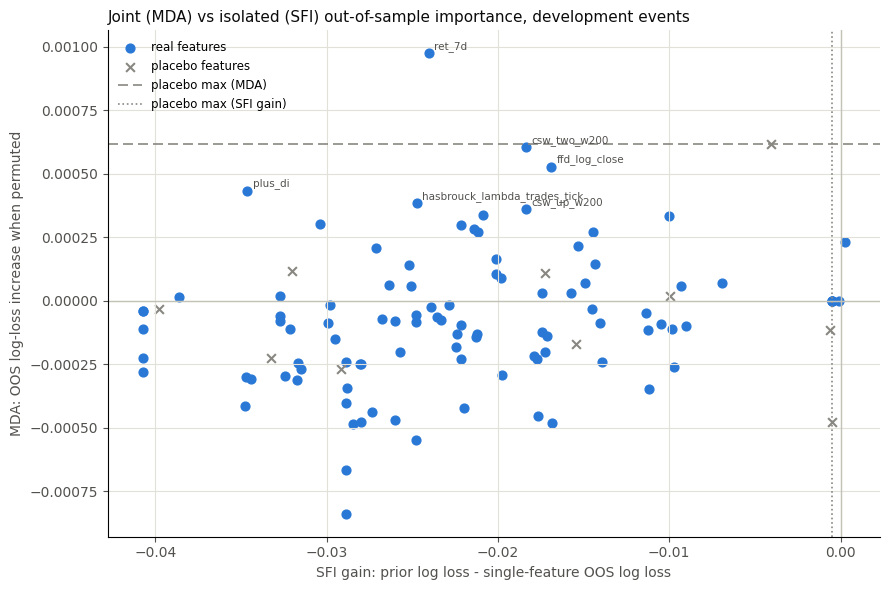

In [18]:
SERIES = {"real": dict(color="#2a78d6", marker="o"), "placebo": dict(color="#898781", marker="x")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

def style(ax, xlabel, ylabel, title):
    ax.set_xlabel(xlabel, color=MUTED); ax.set_ylabel(ylabel, color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.grid(color=GRID, lw=0.8); ax.tick_params(colors=MUTED)
    for s in ("top", "right"): ax.spines[s].set_visible(False)

fig, ax = plt.subplots(figsize=(9, 6))
for kind, mask in [("real", ~is_pl), ("placebo", is_pl)]:
    ax.scatter(imp.loc[mask, "sfi_gain"], imp.loc[mask, "mda"], s=40, label=f"{kind} features", **SERIES[kind])
ax.axhline(thr["mda"], color="#898781", ls=(0, (6, 3)), lw=1.2, label="placebo max (MDA)")
ax.axvline(thr["sfi_gain"], color="#898781", ls=":", lw=1.2, label="placebo max (SFI gain)")
ax.axhline(0, color="#c3c2b7", lw=1); ax.axvline(0, color="#c3c2b7", lw=1)
for c in imp.loc[REAL].sort_values("mda", ascending=False).index[:6]:
    ax.annotate(c, (imp.at[c, "sfi_gain"], imp.at[c, "mda"]), fontsize=7.5, color=MUTED, xytext=(4, 3), textcoords="offset points")
style(ax, "SFI gain: prior log loss - single-feature OOS log loss", "MDA: OOS log-loss increase when permuted",
      "Joint (MDA) vs isolated (SFI) out-of-sample importance, development events")
ax.legend(frameon=False, fontsize=8.5); fig.tight_layout(); plt.show()

### 4.4 Substitution effects and joint usefulness: clustered MDA and family MDA

**Clustered MDA** (*my choice*): in each fold the training rows are clustered (`1 − |ρ|`, section 3) and each cluster's columns are permuted **jointly**.
A cluster of substitutes that individually show MDA ≈ 0 (because each can stand in for the others) is then measured as a whole. Placebos enter as
singleton groups.

**Family MDA**: the same joint permutation over each registry family (a-priori grouping, no fitting), with all placebos permuted together as one
reference group of the same kind.

Comparison with the single-feature numbers:

* group MDA clearly above the **sum** of its members' single MDAs → substitution inside the group (members hide each other);
* single-feature SFI above the placebos but MDA ≈ 0 → information that the other features already carry;
* MDA above the placebos with SFI ≈ prior → usefulness only in combination (joint or hierarchical effects, AFML §8.4.1).

In [19]:
t = time.time()
def cluster_groups_with_placebos(Z):
    real = [c for c in Z.columns if not c.startswith("placebo_")]
    g = cluster_groups(spearman_clusters(Z[real]))
    g.update({c: [c] for c in Z.columns if c.startswith("placebo_")})
    return g

cmda_folds, cmda_members = permutation_importance_cv(X_dev, y_dev, t1_dev, cluster_groups_with_placebos, N_SPLITS, N_PERM, SEED,
                                                      extra_fn=placebo_maker(N_PLACEBO))
# attribute each fold's cluster MDA to its member features, then average per feature over folds
long = cmda_members.merge(cmda_folds.drop(columns=["_base_logloss", "_prior_logloss", "_auc"]).stack().rename("cluster_mda").reset_index()
                          .rename(columns={"level_1": "group"}), on=["fold", "group"])
cl_size = cmda_members.groupby(["fold", "group"]).size().rename("cluster_size").reset_index()
long = long.merge(cl_size, on=["fold", "group"])
per_feat = long.groupby("feature").agg(cluster_mda=("cluster_mda", "mean"), cluster_size=("cluster_size", "mean"))
pl_max_c = per_feat.loc[per_feat.index.str.startswith("placebo_"), "cluster_mda"].max()
real_feat = per_feat.loc[~per_feat.index.str.startswith("placebo_")]
print(f"clustered MDA: placebo max {pl_max_c:.5f}; real features whose cluster beats it: "
      f"{int((real_feat['cluster_mda'] > pl_max_c).sum())} of {len(real_feat)} (features, not clusters)")

# per dev-level cluster: mean of member-attributed cluster MDA, vs sum of single-feature MDA
cl_tab = pd.DataFrame([{"cluster": g, "size": len(m), "families": ", ".join(sorted({FAMILY.get(c, '?') for c in m})),
                        "clustered_mda (fold clusters)": real_feat.reindex(m)["cluster_mda"].mean(),
                        "sum of single MDA": imp.loc[m, "mda"].sum(), "max single SFI gain": imp.loc[m, "sfi_gain"].max()}
                       for g, m in groups_dev.items()]).set_index("cluster").sort_values("clustered_mda (fold clusters)", ascending=False)
display(cl_tab.head(15).round(5))
print(f"{time.time() - t:.0f} s")

clustered MDA: placebo max 0.00148; real features whose cluster beats it: 0 of 99 (features, not clusters)


,size,families,clustered_mda (fold clusters),sum of single MDA,max single SFI gain
cluster,,,,,
cl:csw_two_w200 (+1),2,structural_csw,0.00132,0.00097,-0.01835
cl:ret_1d,1,returns,0.00061,0.00030,-0.03040
cl:ret_7d,1,returns,0.00047,0.00097,-0.02404
cl:di_diff (+1),2,strategy_native,0.00044,0.00051,-0.01492
cl:long_breakout_atr,1,strategy_native,0.00043,0.00023,0.00025
cl:kyle_lambda_bars50_aggr_rel (+1),2,lambda,0.00038,0.00020,-0.01530
cl:ret_1h (+3),4,"realized_vol, returns",0.00036,-0.00118,-0.02477
cl:ret_1h_ref_age_s,1,returns,0.00035,-0.00007,-0.02678
cl:sdfc_w200_trim15,1,structural_sdfc,0.00033,0.00027,-0.02117


7 s


In [20]:
t = time.time()
fam_groups_all = {}
for c in MODEL_COLUMNS:
    fam_groups_all.setdefault(FAMILY[c], []).append("ffd_log_close" if c.startswith("ffd_d") else c)
fam_groups_all = {k: sorted(set(v)) for k, v in fam_groups_all.items()}
def family_groups(Z):
    g = {f"fam:{k}": [c for c in v if c in Z.columns] for k, v in fam_groups_all.items()}
    g = {k: v for k, v in g.items() if v}
    g["fam:PLACEBO (all placebos)"] = [c for c in Z.columns if c.startswith("placebo_")]
    return g
fmda_folds, fmda_members = permutation_importance_cv(X_dev, y_dev, t1_dev, family_groups, N_SPLITS, N_PERM, SEED,
                                                      extra_fn=placebo_maker(N_PLACEBO))
F = fmda_folds.drop(columns=["_base_logloss", "_prior_logloss", "_auc"])
fam = pd.DataFrame({"family_mda": F.mean(), "se": F.std() / np.sqrt(N_SPLITS), "folds_positive": (F > 0).sum(),
                    "n_features_used": fmda_members.groupby("group")["feature"].nunique()})
_fg = family_groups(ZP_dev)
fam["sum_single_mda"] = [imp.loc[[c for c in _fg.get(g, []) if c in imp.index], "mda"].sum() for g in fam.index]
fam = fam.sort_values("family_mda", ascending=False)
display(fam.round(5))
print(f"{time.time() - t:.0f} s")

,family_mda,se,folds_positive,n_features_used,sum_single_mda
fam:strategy_native,0.00077,0.00093,3,7,0.00046
fam:ffd,0.00062,0.00061,2,1,0.00053
fam:funding,0.00056,0.00021,4,3,0.00032
fam:structural_csw,0.00033,0.00029,3,3,0.00048
fam:basis,0.00027,0.00030,4,3,-0.00035
fam:structural_sdfc,0.00014,0.00043,3,2,0.00025
fam:duration,0.00000,0.00008,3,2,-0.00014
fam:trend,-0.00013,0.00008,2,1,-0.00023
fam:intensity,-0.00020,0.00021,2,3,-0.00065
fam:structural_sadf,-0.00026,0.00038,1,4,-0.00040


6 s


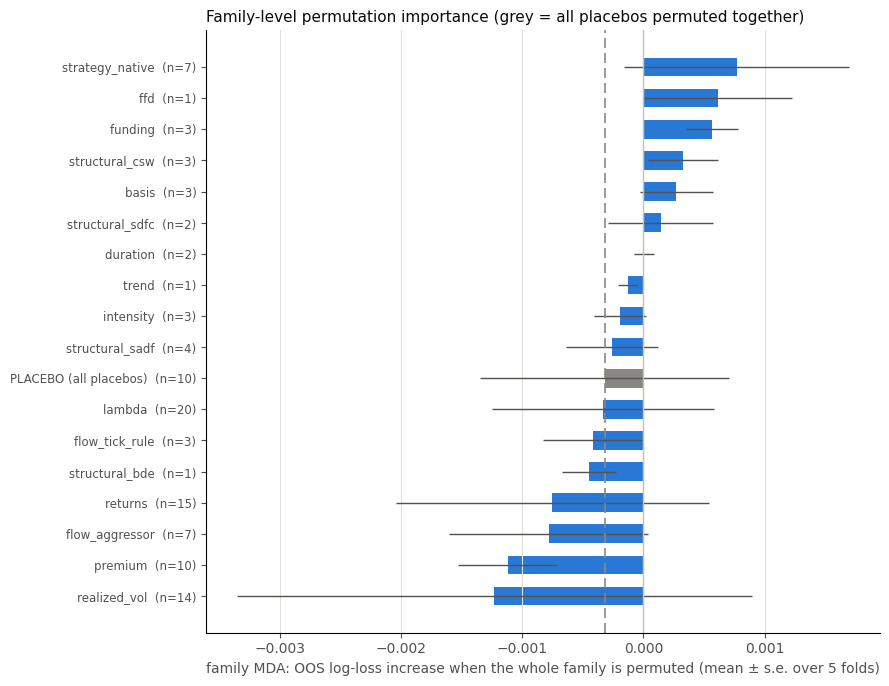

In [21]:
fig, ax = plt.subplots(figsize=(9, 0.32 * len(fam) + 1.2))
order = fam.sort_values("family_mda").index
colors = ["#898781" if "PLACEBO" in g else "#2a78d6" for g in order]
ax.barh(range(len(order)), fam.loc[order, "family_mda"], xerr=fam.loc[order, "se"], color=colors, height=0.6,
        error_kw=dict(ecolor=MUTED, lw=1))
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{g[4:]}  (n={int(fam.at[g, 'n_features_used'])})" for g in order], fontsize=8.5)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.axvline(fam.loc["fam:PLACEBO (all placebos)", "family_mda"], color="#898781", ls=(0, (6, 3)), lw=1.2)
style(ax, "family MDA: OOS log-loss increase when the whole family is permuted (mean ± s.e. over 5 folds)", "",
      "Family-level permutation importance (grey = all placebos permuted together)")
ax.grid(axis="y", visible=False); fig.tight_layout(); plt.show()

### 4.5 Orthogonal features and PCA-rank consistency (AFML §8.4.2, Snippets 8.5–8.6)

Standardise the usable development features, keep the principal components explaining 95 % of the variance, fit `RF_MDI` on them and compute the
weighted Kendall's τ between MDI and the inverse PCA rank. AFML reads a high τ as evidence that the supervised importance agrees with the unsupervised
structure. *My addition*: τ is also computed for `N_TAU_NULL` label permutations, because with weak labels a positive τ can arise from feature shape alone
(MDI favours high-variance, continuous inputs).

In [22]:
t = time.time()
Zs = StandardScaler().fit_transform(Z_dev)
pca = PCA(n_components=PCA_VAR, svd_solver="full").fit(Zs)
Pdev = pd.DataFrame(pca.transform(Zs), index=Z_dev.index, columns=[f"PC_{i + 1}" for i in range(pca.n_components_)])
inv_rank = 1.0 / np.arange(1, pca.n_components_ + 1)

def pc_mdi(yv, seed):
    fit = rf_mdi(seed).fit(Pdev, yv)
    m = pd.DataFrame([tr.feature_importances_ for tr in fit.estimators_]).replace(0, np.nan).mean()
    return (m / m.sum()).to_numpy()

mdi_pc = pc_mdi(y_dev, SEED)
tau = weightedtau(mdi_pc, inv_rank)[0]
rng_tau = np.random.default_rng(SEED)
tau_null = np.array([weightedtau(pc_mdi(pd.Series(rng_tau.permutation(y_dev.to_numpy()), index=y_dev.index), SEED + 1 + i), inv_rank)[0]
                     for i in range(N_TAU_NULL)])
print(f"{Z_dev.shape[1]} features -> {pca.n_components_} PCs for {PCA_VAR:.0%} variance (PC1 {pca.explained_variance_ratio_[0]:.1%})")
print(f"weighted Kendall tau(MDI on PCs, inverse PCA rank) = {tau:.3f}; label-permutation null: mean {tau_null.mean():.3f}, "
      f"95th pct {np.quantile(tau_null, 0.95):.3f}, share of null >= observed {np.mean(tau_null >= tau):.2f}")
loadings = pd.DataFrame(pca.components_[:5].T, index=Z_dev.columns, columns=Pdev.columns[:5])
print("Top-loading features of the first 5 PCs:")
display(pd.DataFrame({pc: [f"{i} ({loadings.at[i, pc]:+.2f})" for i in loadings[pc].abs().sort_values(ascending=False).index[:4]]
                      for pc in loadings.columns}))
print(f"{time.time() - t:.0f} s")

99 features -> 42 PCs for 95% variance (PC1 16.8%)
weighted Kendall tau(MDI on PCs, inverse PCA rank) = -0.164; label-permutation null: mean -0.001, 95th pct 0.262, share of null >= observed 0.85
Top-loading features of the first 5 PCs:


,PC_1,PC_2,PC_3,PC_4,PC_5
0,hasbrouck_lambda_bars50_tick (+0.20),aggr_imbalance_volume (+0.21),hasbrouck_tstat_trades_aggr (+0.23),aggr_signed_volume (+0.24),kyle_lambda_trades_aggr_rel (+0.26)
1,rvol_1h (+0.19),aggr_imbalance_notional (+0.21),avg_trade_size (-0.23),aggr_sell_volume (-0.24),kyle_lambda_trades_tick_rel (+0.26)
2,rvol_ann_1h (+0.19),tick_imbalance_volume (+0.21),ffd_log_close (+0.23),aggr_imbalance_notional (+0.24),long_breakout_atr (+0.20)
3,rvol_7d (+0.19),tick_imbalance_notional (+0.21),hasbrouck_tstat_trades_tick (+0.22),aggr_imbalance_volume (+0.24),hasbrouck_lambda_trades_aggr (+0.19)


51 s


## 5. Nested comparison of feature sets — same classifier, same outer folds

Outer loop: the same 5 `PurgedKFold` folds on the development events. For each outer fold, **everything below is fitted on the outer training
partition only**, then the held-out fold is predicted once:

| Set | Definition (fixed before any result) | Why it is a candidate |
|---|---|---|
| **A. full** | all eligible columns that pass the training coverage / constant filter (+ `ffd_log_close`) | reference |
| **B. incumbent** | the 13 inputs of the existing workflow (4 strategy features + 9 bar features) | the set currently in use |
| **C. cluster representatives** | one medoid per Spearman cluster of the training partition | unsupervised redundancy removal: same information, fewer substitutes |
| **D. clustered-MDA selection** | clusters whose **joint** permutation MDA (inner `PurgedKFold`, 4 folds, rebuilt on the training subset) is > 0 and above every placebo; all members of the selected clusters. If nothing passes, the model is the training prior (no feature has value) | supervised selection that accounts for substitution and joint effects |
| **E. PCA 95 %** | standardised training features → principal components for 95 % of the variance | AFML's orthogonalisation |

Every set uses `RF_EVAL` with the same hyper-parameters. Seeds `SEEDS` change the forest and the placebo/permutation draws; the reported OOF probability per
event is the mean over seeds. The prior (training share) is the no-information reference.

In [23]:
INCUMBENT = ["adx_value", "di_diff", "long_breakout_atr", "ema_distance", "aggr_imbalance_notional", "tick_imbalance_volume", "ret_1h", "ret_4h",
             "premium_fx_coinbase_btc_1m", "trend_30d_volscaled", "ret_30d", "rvol_7d", "premium_raw_coinbase_btc_1d_z90"]
assert set(INCUMBENT) <= set(ELIGIBLE)

class FeatureSetModel(BaseEstimator, ClassifierMixin):
    # prep (training rows) -> feature-set construction (training rows) -> RF_EVAL; kind in full | fixed | cluster_reps | cluster_mda | pca
    def __init__(self, kind="full", columns=None, seed=SEED, t1=None):
        self.kind, self.columns, self.seed, self.t1 = kind, columns, seed, t1

    def fit(self, X, y):
        self.prep_ = TrainOnlyPrep(columns=self.columns, ffd_daily=FFD_DAILY).fit(X)
        Z = self.prep_.transform(X)
        self.selected_groups_ = None
        if self.kind in ("full", "fixed"):
            self.cols_ = list(Z.columns)
        elif self.kind == "cluster_reps":
            self.cols_ = medoids(Z, spearman_clusters(Z))
        elif self.kind == "cluster_mda":
            groups = cluster_groups(spearman_clusters(Z))
            rng = np.random.default_rng(self.seed)
            P = make_placebos(Z, N_PLACEBO, rng)
            ZP = pd.concat([Z, P], axis=1)
            allg = {**groups, **{c: [c] for c in P.columns}}
            inner, _ = permutation_importance_cv(ZP, y, self.t1.loc[X.index], lambda _Z: allg, INNER_SPLITS, N_PERM_INNER, self.seed, prep=False)
            m = inner.drop(columns=["_base_logloss", "_prior_logloss", "_auc"]).mean()
            pl_max = m[list(P.columns)].max()
            self.inner_mda_, self.placebo_max_ = m, pl_max
            self.selected_groups_ = [g for g in groups if m.get(g, -np.inf) > max(pl_max, 0.0)]
            self.cols_ = [c for g in self.selected_groups_ for c in groups[g]]
        elif self.kind == "pca":
            self.cols_ = list(Z.columns)
            self.scaler_ = StandardScaler().fit(Z)
            self.pca_ = PCA(n_components=PCA_VAR, svd_solver="full").fit(self.scaler_.transform(Z))
        self.prior_ = float(np.mean(y))
        self.classes_ = np.array([0, 1])
        if not self.cols_:
            self.clf_ = None
            return self
        self.clf_ = rf_eval(self.seed).fit(self._design(Z), y)
        return self

    def _design(self, Z):
        if self.kind == "pca":
            return self.pca_.transform(self.scaler_.transform(Z[self.cols_]))
        return Z[self.cols_]

    def predict_proba(self, X):
        if self.clf_ is None:
            p = np.full(len(X), self.prior_)
        else:
            p = p1(self.clf_, self._design(self.prep_.transform(X)))
        return np.column_stack([1 - p, p])

    def n_inputs(self):
        return self.pca_.n_components_ if self.kind == "pca" else len(self.cols_)

SETS = {
    "A. full": dict(kind="full"),
    "B. incumbent": dict(kind="fixed", columns=INCUMBENT),
    "C. cluster representatives": dict(kind="cluster_reps"),
    "D. clustered-MDA selection": dict(kind="cluster_mda"),
    "E. PCA 95%": dict(kind="pca"),
}

In [24]:
t = time.time()
oof = {name: np.zeros((len(SEEDS), len(X_dev))) for name in SETS}
oof_prior = np.full(len(X_dev), np.nan)
set_log = []
for k, f in enumerate(folds):
    oof_prior[f.test] = y_dev.iloc[f.train].mean()
    for si, seed in enumerate(SEEDS):
        for name, kw in SETS.items():
            m = FeatureSetModel(seed=seed, t1=t1_dev, **kw).fit(X_dev.iloc[f.train], y_dev.iloc[f.train])
            oof[name][si, f.test] = m.predict_proba(X_dev.iloc[f.test])[:, 1]
            set_log.append({"fold": k, "seed": seed, "set": name, "n_inputs": m.n_inputs(), "ffd_d": m.prep_.ffd_d_,
                            "selected": list(m.cols_) if kw["kind"] in ("cluster_mda", "cluster_reps") else None,
                            "selected_groups": m.selected_groups_})
set_log = pd.DataFrame(set_log)
print(f"nested comparison: {time.time() - t:.0f} s")
set_log.pivot_table(index="set", columns="fold", values="n_inputs", aggfunc=["min", "max"])

nested comparison: 138 s


min                 max                
fold                         0   1   2   3   4   0   1   2   3   4
set                                                               
A. full                     98  99  99  99  99  98  99  99  99  99
B. incumbent                13  13  13  13  13  13  13  13  13  13
C. cluster representatives  46  49  48  51  49  46  49  48  51  49
D. clustered-MDA selection   0  16  26   0   0  16  36  36   1  26
E. PCA 95%                  41  41  41  42  41  41  41  41  42  41

### 5.1 Pooled out-of-fold scores

Seed-averaged OOF probabilities. CIs come from a **monthly block bootstrap** of the events (`N_BOOT` resamples of calendar months with replacement), paired
across sets, so a Δ CI is for the difference on the same resampled events. The bootstrap treats the fitted OOF predictions as fixed. It does not
capture refitting variance; the seed spread and the per-fold table show that part.

In [25]:
y_arr = y_dev.to_numpy()
month = dev.index.tz_convert(None).to_period("M")
month_ids = pd.factorize(month)[0]
months = np.unique(month_ids)
idx_by_month = [np.flatnonzero(month_ids == m) for m in months]
rng_b = np.random.default_rng(SEED)
BOOT_IDX = [np.concatenate([idx_by_month[i] for i in rng_b.integers(0, len(months), len(months))]) for _ in range(N_BOOT)]

def scores(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p),
            "auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan}

def boot_delta(y, pa, pb, boot_idx):
    # bootstrap distribution of score(pb) - score(pa) on the same resampled events
    out = []
    for ix in boot_idx:
        sa, sb = scores(y[ix], pa[ix]), scores(y[ix], pb[ix])
        out.append([sb["log_loss"] - sa["log_loss"], sb["auc"] - sa["auc"]])
    return np.array(out)

P_mean = {name: v.mean(axis=0) for name, v in oof.items()}
rows = []
for name, p in {**P_mean, "prior (training share)": oof_prior}.items():
    s = scores(y_arr, p)
    per_seed = [scores(y_arr, oof[name][i])["log_loss"] for i in range(len(SEEDS))] if name in oof else [s["log_loss"]]
    per_seed_auc = [scores(y_arr, oof[name][i])["auc"] for i in range(len(SEEDS))] if name in oof else [s["auc"]]
    r = {"set": name, **s, "log_loss seed range": f"{min(per_seed):.4f}–{max(per_seed):.4f}", "auc seed range": f"{min(per_seed_auc):.3f}–{max(per_seed_auc):.3f}"}
    if name != "A. full":
        d = boot_delta(y_arr, P_mean["A. full"], p, BOOT_IDX)
        r.update({"Δlog_loss vs A": s["log_loss"] - scores(y_arr, P_mean["A. full"])["log_loss"],
                  "Δlog_loss 95% CI": f"[{np.quantile(d[:, 0], 0.025):+.4f}, {np.quantile(d[:, 0], 0.975):+.4f}]",
                  "ΔAUC vs A": s["auc"] - scores(y_arr, P_mean["A. full"])["auc"],
                  "ΔAUC 95% CI": f"[{np.quantile(d[:, 1], 0.025):+.3f}, {np.quantile(d[:, 1], 0.975):+.3f}]"})
    lo, hi = np.quantile([scores(y_arr[ix], p[ix])["auc"] for ix in BOOT_IDX[:500]], [0.025, 0.975])
    r["auc 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
    rows.append(r)
cmp_dev = pd.DataFrame(rows).set_index("set")
print(f"development OOF, {len(y_arr)} events, {len(months)} months; lower log loss / Brier is better; Δ < 0 in log loss = better than A")
cmp_dev.round(4)

development OOF, 763 events, 42 months; lower log loss / Brier is better; Δ < 0 in log loss = better than A


,log_loss,brier,auc,log_loss seed range,auc seed range,auc 95% CI,Δlog_loss vs A,Δlog_loss 95% CI,ΔAUC vs A,ΔAUC 95% CI
set,,,,,,,,,,
A. full,0.7008,0.2538,0.4798,0.7003–0.7020,0.473–0.483,"[0.440, 0.530]",NaN,NaN,NaN,NaN
B. incumbent,0.7056,0.2561,0.4725,0.7048–0.7071,0.466–0.480,"[0.435, 0.510]",0.0048,"[-0.0033, +0.0132]",-0.0073,"[-0.050, +0.032]"
C. cluster representatives,0.6973,0.2520,0.4996,0.6972–0.6978,0.497–0.502,"[0.460, 0.549]",-0.0035,"[-0.0075, +0.0002]",0.0199,"[-0.002, +0.042]"
D. clustered-MDA selection,0.7070,0.2568,0.4600,0.7068–0.7167,0.454–0.474,"[0.426, 0.497]",0.0061,"[-0.0026, +0.0148]",-0.0198,"[-0.065, +0.020]"
E. PCA 95%,0.6945,0.2507,0.5098,0.6935–0.6957,0.507–0.513,"[0.473, 0.543]",-0.0064,"[-0.0164, +0.0049]",0.0300,"[-0.034, +0.085]"
prior (training share),0.6927,0.2498,0.4790,0.6927–0.6927,0.479–0.479,"[0.446, 0.513]",-0.0082,"[-0.0178, +0.0019]",-0.0007,"[-0.070, +0.062]"


In [26]:
# per-fold log loss (seed-averaged probabilities) and difference to A
fold_rows = []
for k, f in enumerate(folds):
    yk = y_arr[f.test]
    for name, p in {**P_mean, "prior": oof_prior}.items():
        s = scores(yk, p[f.test])
        fold_rows.append({"fold": k, "set": name, "log_loss": s["log_loss"], "auc": s["auc"]})
fold_scores = pd.DataFrame(fold_rows)
ll_pivot = fold_scores.pivot(index="set", columns="fold", values="log_loss")
d_pivot = ll_pivot.sub(ll_pivot.loc["A. full"], axis=1)
d_pivot["folds better than A"] = (d_pivot < 0).sum(axis=1)
print("Per-fold OOF log loss:"); display(ll_pivot.round(4))
print("Per-fold Δ log loss vs A (negative = better than A):"); display(d_pivot.round(4))
print("Per-fold AUC:"); display(fold_scores.pivot(index="set", columns="fold", values="auc").round(3))

Per-fold OOF log loss:


fold,0,1,2,3,4
set,,,,,
A. full,0.6964,0.7073,0.7035,0.6903,0.7066
B. incumbent,0.7047,0.7015,0.7157,0.7015,0.7046
C. cluster representatives,0.6964,0.7047,0.6992,0.6826,0.7036
D. clustered-MDA selection,0.6987,0.7091,0.7211,0.7014,0.7045
E. PCA 95%,0.6938,0.6923,0.6990,0.6892,0.6979
prior,0.6911,0.6917,0.6933,0.6907,0.6966


Per-fold Δ log loss vs A (negative = better than A):


fold,0,1,2,3,4,folds better than A
set,,,,,,
A. full,0.0000,0.0000,0.0000,0.0000,0.0000,0
B. incumbent,0.0083,-0.0058,0.0122,0.0111,-0.0021,2
C. cluster representatives,-0.0000,-0.0026,-0.0043,-0.0077,-0.0031,5
D. clustered-MDA selection,0.0023,0.0018,0.0176,0.0111,-0.0021,1
E. PCA 95%,-0.0026,-0.0150,-0.0044,-0.0011,-0.0087,5
prior,-0.0053,-0.0156,-0.0102,0.0003,-0.0101,4


Per-fold AUC:


fold,0,1,2,3,4
set,,,,,
A. full,0.499,0.472,0.453,0.545,0.457
B. incumbent,0.508,0.503,0.394,0.493,0.477
C. cluster representatives,0.507,0.469,0.479,0.601,0.481
D. clustered-MDA selection,0.486,0.484,0.396,0.502,0.462
E. PCA 95%,0.526,0.550,0.474,0.514,0.529
prior,0.500,0.500,0.500,0.500,0.500


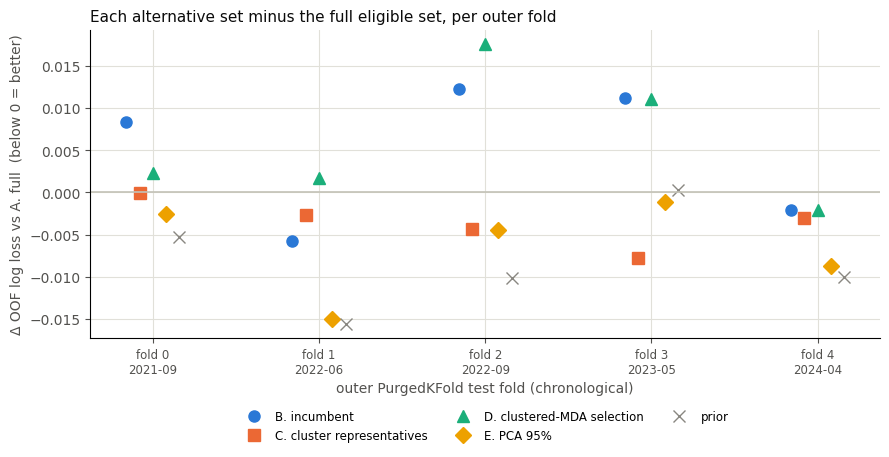

In [27]:
SET_STYLE = {"B. incumbent": dict(color="#2a78d6", marker="o"), "C. cluster representatives": dict(color="#eb6834", marker="s"),
             "D. clustered-MDA selection": dict(color="#1baf7a", marker="^"), "E. PCA 95%": dict(color="#eda100", marker="D"),
             "prior": dict(color="#898781", marker="x")}
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (name, st) in enumerate(SET_STYLE.items()):
    ax.plot(np.arange(N_SPLITS) + (i - 2) * 0.08, d_pivot.loc[name, list(range(N_SPLITS))], ls="none", ms=8, label=name, **st)
ax.axhline(0, color="#c3c2b7", lw=1.2)
ax.set_xticks(range(N_SPLITS)); ax.set_xticklabels([f"fold {k}\n{folds[k].test_start:%Y-%m}" for k in range(N_SPLITS)], fontsize=8.5)
style(ax, "outer PurgedKFold test fold (chronological)", "Δ OOF log loss vs A. full  (below 0 = better)",
      "Each alternative set minus the full eligible set, per outer fold")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3); fig.tight_layout(); plt.show()

### 5.2 What the supervised selection picked, and how stable it is

For set D, the share of (outer fold × seed) fits in which each feature was selected. Stable selection would mean the same clusters in most fits.

In [28]:
D = set_log[set_log["set"] == "D. clustered-MDA selection"]
n_fits = len(D)
sel_counts = pd.Series([c for cols in D["selected"] for c in cols]).value_counts()
print(f"set D: {int((D['n_inputs'] == 0).sum())} of {n_fits} fits selected nothing (-> prior); "
      f"inputs per fit: min {D['n_inputs'].min()}, median {D['n_inputs'].median():.0f}, max {D['n_inputs'].max()}")
if len(sel_counts):
    tab = (sel_counts / n_fits).rename("selection share").to_frame()
    tab["family"] = [FAMILY.get(c, "?") for c in tab.index]
    tab["descriptive MDA (sec. 4.3)"] = imp.reindex(tab.index)["mda"]
    display(tab.head(25).round(3))
C = set_log[set_log["set"] == "C. cluster representatives"]
print(f"set C: representatives per fit min {C['n_inputs'].min()}, max {C['n_inputs'].max()}; "
      f"set A inputs per fit {set_log.loc[set_log['set'] == 'A. full', 'n_inputs'].min()}–{set_log.loc[set_log['set'] == 'A. full', 'n_inputs'].max()}")

set D: 3 of 15 fits selected nothing (-> prior); inputs per fit: min 0, median 16, max 36


,selection share,family,descriptive MDA (sec. 4.3)
ret_7d,0.600,returns,0.001
ret_1h,0.400,returns,-0.000
rv_1h,0.400,realized_vol,-0.000
rvol_1h,0.400,realized_vol,-0.000
rvol_ann_1h,0.400,realized_vol,-0.001
long_breakout_atr,0.333,strategy_native,0.000
hasbrouck_lambda_trades_tick,0.333,lambda,0.000
kyle_lambda_trades_aggr_rel,0.333,lambda,0.000
hasbrouck_lambda_trades_aggr,0.333,lambda,-0.000
kyle_lambda_bars50_aggr_rel,0.333,lambda,-0.000


set C: representatives per fit min 46, max 51; set A inputs per fit 98–99


## 6. Final test — each set's procedure fitted once on all development events

Each procedure (including the inner selection of D, with `PurgedKFold` rebuilt on all development events) is fitted on the development set and scored
**once** on the last 30 % of trades. Nothing here feeds back into any choice above. Note: the existing threshold notebook has already evaluated
models on these test trades (not feature sets), so the test is unseen *for feature selection* but not pristine for this dataset. 328 events give wide intervals.

In [29]:
t = time.time()
y_te = y_test.to_numpy()
p_test, test_inputs = {}, {}
for name, kw in SETS.items():
    ps = []
    for seed in SEEDS:
        m = FeatureSetModel(seed=seed, t1=t1_dev, **kw).fit(X_dev, y_dev)
        ps.append(m.predict_proba(X_test)[:, 1])
        test_inputs.setdefault(name, []).append(m.n_inputs())
    p_test[name] = np.mean(ps, axis=0)
p_test["prior (training share)"] = np.full(len(y_te), y_dev.mean())

tmonth = pd.factorize(test_events.index.tz_convert(None).to_period("M"))[0]
tm = np.unique(tmonth)
t_idx = [np.flatnonzero(tmonth == m) for m in tm]
rng_t = np.random.default_rng(SEED + 7)
BOOT_T = [np.concatenate([t_idx[i] for i in rng_t.integers(0, len(tm), len(tm))]) for _ in range(N_BOOT)]
rows = []
for name, p in p_test.items():
    s = scores(y_te, p)
    r = {"set": name, **s, "inputs (per seed)": test_inputs.get(name, "-")}
    if name != "A. full":
        d = boot_delta(y_te, p_test["A. full"], p, BOOT_T)
        r.update({"Δlog_loss vs A": s["log_loss"] - scores(y_te, p_test["A. full"])["log_loss"],
                  "Δlog_loss 95% CI": f"[{np.quantile(d[:, 0], 0.025):+.4f}, {np.quantile(d[:, 0], 0.975):+.4f}]",
                  "ΔAUC vs A": s["auc"] - scores(y_te, p_test["A. full"])["auc"],
                  "ΔAUC 95% CI": f"[{np.quantile(d[:, 1], 0.025):+.3f}, {np.quantile(d[:, 1], 0.975):+.3f}]"})
    rows.append(r)
cmp_test = pd.DataFrame(rows).set_index("set")
print(f"final test: {len(y_te)} events, profitable share {y_te.mean():.3f}, {len(tm)} months; {time.time() - t:.0f} s")
cmp_test.round(4)

final test: 328 events, profitable share 0.488, 19 months; 68 s


,log_loss,brier,auc,inputs (per seed),Δlog_loss vs A,Δlog_loss 95% CI,ΔAUC vs A,ΔAUC 95% CI
set,,,,,,,,
A. full,0.6955,0.2512,0.5164,"[99, 99, 99]",NaN,NaN,NaN,NaN
B. incumbent,0.6914,0.2491,0.5400,"[13, 13, 13]",-0.0041,"[-0.0127, +0.0041]",0.0236,"[-0.032, +0.088]"
C. cluster representatives,0.6941,0.2505,0.5265,"[48, 48, 48]",-0.0014,"[-0.0042, +0.0017]",0.0101,"[-0.009, +0.035]"
D. clustered-MDA selection,0.7016,0.2542,0.4715,"[20, 31, 6]",0.0061,"[-0.0005, +0.0135]",-0.0449,"[-0.095, -0.000]"
E. PCA 95%,0.6954,0.2511,0.4950,"[42, 42, 42]",-0.0002,"[-0.0131, +0.0115]",-0.0214,"[-0.097, +0.062]"
prior (training share),0.6930,0.2499,0.5000,-,-0.0025,"[-0.0116, +0.0074]",-0.0164,"[-0.066, +0.034]"


In [30]:
print(f"total runtime {(time.time() - T0) / 60:.1f} min")

total runtime 10.2 min


## 7. Conclusions

The interpretation is in the markdown cell below. It was written after this execution and quotes the tables above. If the notebook is re-run on another
dataset, re-read the tables rather than the text.

### Summary of this execution (ETHUSDT volume bars `6a915d3a25d574ce`, STRATEGY_432_BTC, 763 development / 328 test trades)

**1. No feature, cluster or family shows reliable out-of-sample information about `trade_return > 0`.**

* With the full eligible set, the development OOF log loss is **0.7008** against **0.6927** for the prior (training share); the prior wins in 4 of 5 folds. OOF AUC is
  **0.480** (monthly-block 95 % CI 0.440–0.530).
* Counts of real features above the placebo maximum (99 usable features, 10 placebos, about **9 expected by chance**): MDA **1**, MDI **8**, SFI gain **6**,
  SFI |AUC − 0.5| **0**, clustered MDA **0**. No feature passes two criteria.
* Rank agreement between methods is low: Spearman 0.20 (MDI–MDA), −0.13 (MDI–SFI), 0.30 (MDA–SFI).
* AFML's confirmation check fails as well. The weighted Kendall τ between PC-MDI and PCA rank is **−0.16**, while the label-permutation null has a 95th
  percentile of 0.26. This is what the book would read as importance with no structure behind it.

**2. Features or groups that "appear useful" are weak candidates, not findings.**

* The only feature above the placebo maximum on MDA is `ret_7d` (MDA 0.0010, about 4.8 fold-standard-errors). Its SFI is worse than the prior and its
  single-feature AUC is 0.517. One feature out of 99 is fewer than the 9 expected by chance.
* At family level (section 4.4), only `funding` is positive in 4 of 5 folds (0.00056 ± 0.00021). It contains `funding_rate_last_age_s`, which is the position
  in the 8-hour funding cycle (time of day). This is 1 of 18 family tests, with no multiplicity correction.
* `strategy_native` (0.00077 ± 0.00093) and `ffd` (0.00062 ± 0.00061) have the largest point estimates but are within one or two standard errors of zero.
* These are hypotheses to check on data after the test period, not features to promote.

**3. Redundant or uninformative.**

* **Redundant (label-free evidence).** The 99 usable features form **48** correlation clusters, and **40** pairs have |ρ| ≥ 0.99:
  * `rv` / `rvol` / `rvol_ann` at each horizon;
  * volume vs. notional imbalance ratios, and tick-rule vs. aggressor flow;
  * `di_diff` and `plus_di`; `ret_30d` and `trend_30d_volscaled`; `ema_distance` and `csw_down_w200`;
  * the four Kyle/Hasbrouck variants of each estimator.
  
  `ffd_log_close` clusters with `avg_trade_size` and trade counts. These are slow price-level or regime proxies.
* **Uninformative.** Permuting `realized_vol`, `premium`, `flow_aggressor` or `returns` as a family *lowers* the OOS log loss (negative family MDA). These are the
  families the forest uses most and that hurt most out of sample.
* **Unusable in this build.** ETF flows, DVOL, Fear & Greed and the Binance `quote_*` spreads are a-priori eligible but empty on the events. The L2-book,
  liquidation, execution-cost and options families have no data at all.
* **Substitution check.** No group had a joint (clustered or family) MDA clearly above the sum of its members' MDAs *and* above the placebos, so no important
  substitute group is hidden by correlation. The largest case, the `csw` cluster (0.00132 vs. a 0.00097 sum), is below the placebo maximum of 0.00148.
* **Joint usefulness.** No feature is useful only in combination: high-MDA features have SFI near the placebos (scatter in 4.3), and MDA itself does not beat the placebos.

**4. Does any subset beat the full eligible set?**

* **C (cluster representatives)** and **E (PCA 95 %)** have lower development log loss than A in **5 of 5** folds:
  * C: Δ = −0.0035, 95 % CI [−0.0075, +0.0002];
  * E: Δ = −0.0064, CI [−0.0164, +0.0049].
* That gain is less overfitting, not more signal: neither beats the **prior** (0.6973 and 0.6945 vs. 0.6927), and their AUCs are 0.500 and 0.510. Fewer or
  denser inputs simply pull the forest's probabilities closer to the base rate.
* **B (incumbent 13 features)** is worse than A on development (+0.0048, CI includes 0). On the test it is the only set below the prior (0.6914 vs. 0.6930, AUC
  0.540), but its CI against A includes 0, and the test trades were already used by the threshold notebook.
* **D (clustered-MDA selection)** is the worst set on development (0.7070) and on the test (0.7016; ΔAUC −0.045, CI [−0.095, −0.000]). Its selections are
  unstable: 3 of 15 fits selected nothing, and the most frequent feature (`ret_7d`) was selected in 60 % of fits. Supervised selection on a label with no
  detectable signal adds variance.
* **No tested subset outperforms the full set by a margin the data can resolve, and no set beats the no-information prior.**

**5. Feature engineering from the source.**

* **FFD.** Log price needs d* = 0.5–0.6 on the fold training partitions (0.4 on all development events; ADF −1.93 at d = 0). FFD(d*) keeps a correlation of
  0.94–0.98 with log price, as AFML ch. 5 describes. The resulting feature is not informative here (MDA 0.0005 ± 0.0008).
* **Other source recommendations used without contradicting evidence:** purged CV with embargo, MDI with `max_features=1`, OOS MDA/SFI, and PCA orthogonalisation.
* **Sample weights.** Uniqueness weighting does not apply (no overlapping labels).

### Remaining uncertainty

* **Sample size.** 763 development events and 5 folds: log-loss differences of ±0.005 sit inside the bootstrap intervals. The bootstrap fixes the fitted
  predictions; refit variance shows only through the 3 seeds and the folds.
* **Scope.** One strategy, one asset, one label definition (net return > 0 at the strategy's own exit), and one classifier with fixed hyper-parameters. A
  different learner, a cost-aware label or a different primary model could rank features differently.
* **Coarse null.** With 10 placebos the null is coarse. 18 family tests and about 100 feature tests are not multiplicity-corrected, so isolated positives are expected.
* **Calibration.** `class_weight='balanced_subsample'` (AFML) moves probabilities toward 0.5. With a base rate of 0.48 this costs little log loss, but it does
  affect every set equally.
* **Choices made after seeing a run.** The stale-feed age rule was added after the first execution (documented in section 2), and the conclusions above come
  from the second. All other design choices were fixed before results.
* **Test set.** It was already evaluated by `threshold_picking.ipynb`, so it is unseen *for feature selection* only.

### Source vs. own choices (recap)

* **From AFML:** meta-labeling target form (§3.6); stationarity via FFD and the min-d ADF rule (ch. 5); uniqueness check (ch. 4); RF settings (ch. 6);
  purged K-fold with embargo (ch. 7); MDI / MDA / SFI, PCA orthogonal features and weighted Kendall τ (ch. 8).
* **Mine:**
  * coverage threshold, cluster cut-off, FFD threshold and block rule;
  * the price normalisation of Kyle's λ and the stale-feed age rule;
  * placebos and the label-permutation null;
  * clustered and family MDA;
  * the four alternative sets, the nested design and the monthly block bootstrap.
* **No feature set is claimed to be optimal.** On this evidence the meta-label is not predictable from the available features, so feature selection cannot
  rescue it. The useful outputs are the redundancy map and the negative result.
